In [1]:
import pandas as pd
import numpy as np
import openpyxl
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
import researchpy
import pingouin
import seaborn

import matplotlib.pyplot as plt

In [2]:
file = "Project-Data.xlsx"

dfs = {"bc":[], "db": [], "wq_class": [], "ch": [], "asn": [], "wq_reg": [], "ch_OLD": []}

for df in dfs:
    for i in range(1,6):
        if df in ["bc", "db", "wq_class"]:
            dfs[df].append(pd.read_excel(file, sheet_name=f'{df}_{i}', names=["Task", "Dataset", "Seed", "Method", "Model", "Level", "Mode", "Accuracy"]))
        else:
            dfs[df].append(pd.read_excel(file, sheet_name=f'{df}_{i}', names=["Task", "Dataset", "Seed", "Method", "Model", "Level", "Mode", "MAE", "R2", "MSE"]))


In [4]:
pipipi = pd.concat(dfs["ch"])
pipipi = pipipi[pipipi["Method"]!="base"]
pipiiiii = pipipi[pipipi["Method"] == "sig figs"].reset_index(drop=True)
for col in ["Level", "Model", "Mode"]:
    pipiiiii[col] = pipiiiii[col].astype("category")
pingouin.anova(pipiiiii, "MAE", ["Level", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
pipiiiii


,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE
0,regression,ch,42,sig figs,linreg,1.0,both,53501.405715,0.609496,5.340217e+09
1,regression,ch,42,sig figs,linreg,1.0,training_data_only,51600.852613,0.630978,5.046448e+09
2,regression,ch,42,sig figs,linreg,1.0,testing_data_only,469112.354941,-16.488863,2.391634e+11
3,regression,ch,42,sig figs,linreg,2.0,both,50951.227296,0.642054,4.894972e+09
4,regression,ch,42,sig figs,linreg,2.0,training_data_only,50585.950600,0.643286,4.878131e+09
...,...,...,...,...,...,...,...,...,...,...
295,regression,ch,100,sig figs,rfr,4.0,training_data_only,31244.631270,0.825483,2.336017e+09
296,regression,ch,100,sig figs,rfr,4.0,testing_data_only,31879.081554,0.822054,2.381923e+09
297,regression,ch,100,sig figs,rfr,5.0,both,30009.262684,0.836726,2.185524e+09
298,regression,ch,100,sig figs,rfr,5.0,training_data_only,30018.231023,0.836069,2.194321e+09


In [35]:
classification_keys = ["bc", "db", "wq_class"]
regression_keys = ["ch", "asn", "wq_reg"]

classification_df = pd.concat(
    [pd.concat(dfs[key], ignore_index=True) for key in classification_keys],
    ignore_index=True
)

regression_df = pd.concat(
    [pd.concat(dfs[key], ignore_index=True) for key in regression_keys],
    ignore_index=True
)


In [36]:
classification_nonbase = classification_df[
    classification_df["Method"] != "base"
].copy()

# anova_table_pin_class = pingouin.anova(
#     data=classification_nonbase,
#     dv="Accuracy",
#     between=["Dataset", "Method", "Model", "Mode"],
#     ss_type=2,
#     detailed=True,
#     effsize="np2"
# )

# anova_table_pin_class


In [37]:
regression_nonbase = regression_df[
    regression_df["Method"] != "base"
].copy()

regression_nonbase

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE
1,regression,ch,42,rounding,linreg,-2.0,both,68021.055442,0.395945,8.260559e+09
2,regression,ch,42,rounding,linreg,-2.0,training_data_only,71229.080523,0.389339,8.350896e+09
3,regression,ch,42,rounding,linreg,-2.0,testing_data_only,205303.662399,-2.663042,5.009276e+10
4,regression,ch,42,rounding,linreg,-1.0,both,60265.427026,0.534080,6.371545e+09
5,regression,ch,42,rounding,linreg,-1.0,training_data_only,66694.748900,0.489634,6.979347e+09
...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4.0,training_data_only,0.418250,0.434741,3.547000e-01
4556,regression,wq_reg,100,sig figs,rfr,4.0,testing_data_only,0.415094,0.435262,3.543728e-01
4557,regression,wq_reg,100,sig figs,rfr,5.0,both,0.417500,0.438672,3.522331e-01
4558,regression,wq_reg,100,sig figs,rfr,5.0,training_data_only,0.414000,0.449369,3.455213e-01


In [38]:
base_class = (
    classification_df[classification_df["Method"] == "base"]
    .groupby(["Dataset", "Model"])["Accuracy"]
    .mean()
    .rename("base_acc")
)

classification_df = classification_df.merge(base_class, on=["Dataset", "Model"])
classification_df

,Task,Dataset,Seed,Method,Model,Level,Mode,Accuracy,base_acc
0,classification,bc,42,base,logreg,NaN,base,0.973684,0.973684
1,classification,bc,42,rounding,logreg,-2.0,both,0.938596,0.973684
2,classification,bc,42,rounding,logreg,-2.0,training_data_only,0.938596,0.973684
3,classification,bc,42,rounding,logreg,-2.0,testing_data_only,0.622807,0.973684
4,classification,bc,42,rounding,logreg,-1.0,both,0.964912,0.973684
...,...,...,...,...,...,...,...,...,...
5695,classification,wq_class,100,sig figs,rfc,4.0,training_data_only,0.740625,0.701250
5696,classification,wq_class,100,sig figs,rfc,4.0,testing_data_only,0.709375,0.701250
5697,classification,wq_class,100,sig figs,rfc,5.0,both,0.718750,0.701250
5698,classification,wq_class,100,sig figs,rfc,5.0,training_data_only,0.734375,0.701250


In [39]:
base_reg = (
    regression_df[regression_df["Method"] == "base"]
    .groupby(["Dataset", "Model"])["MAE"]
    .mean()
    .rename("base_MAE")
)

regression_df = regression_df.merge(base_reg, on=["Dataset", "Model"])
regression_df

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,base_MAE
0,regression,ch,42,base,linreg,NaN,base,50330.707901,0.650836,4.774882e+09,50079.474365
1,regression,ch,42,rounding,linreg,-2.0,both,68021.055442,0.395945,8.260559e+09,50079.474365
2,regression,ch,42,rounding,linreg,-2.0,training_data_only,71229.080523,0.389339,8.350896e+09,50079.474365
3,regression,ch,42,rounding,linreg,-2.0,testing_data_only,205303.662399,-2.663042,5.009276e+10,50079.474365
4,regression,ch,42,rounding,linreg,-1.0,both,60265.427026,0.534080,6.371545e+09,50079.474365
...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4.0,training_data_only,0.418250,0.434741,3.547000e-01,0.416944
4556,regression,wq_reg,100,sig figs,rfr,4.0,testing_data_only,0.415094,0.435262,3.543728e-01,0.416944
4557,regression,wq_reg,100,sig figs,rfr,5.0,both,0.417500,0.438672,3.522331e-01,0.416944
4558,regression,wq_reg,100,sig figs,rfr,5.0,training_data_only,0.414000,0.449369,3.455213e-01,0.416944


In [40]:
# classification_df["acc_rel"] = classification_df["Accuracy"] / classification_df["base_acc"]
classification_df["acc_drop"] = (classification_df["base_acc"] - classification_df["Accuracy"]) / classification_df["base_acc"]

classification_nonbase_newwww = classification_df[
    classification_df["Method"] != "base"
].copy()

In [42]:
# regression_df["acc_rel"] = regression_df["MAE"] / regression_df["base_MAE"]
regression_df["acc_drop"] = (regression_df["MAE"] - regression_df["base_MAE"]) / regression_df["base_MAE"]


regression_nonbase_newwww = regression_df[
    regression_df["Method"] != "base"
].copy()
regression_df

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,base_MAE,acc_drop
0,regression,ch,42,base,linreg,NaN,base,50330.707901,0.650836,4.774882e+09,50079.474365,0.005017
1,regression,ch,42,rounding,linreg,-2.0,both,68021.055442,0.395945,8.260559e+09,50079.474365,0.358262
2,regression,ch,42,rounding,linreg,-2.0,training_data_only,71229.080523,0.389339,8.350896e+09,50079.474365,0.422321
3,regression,ch,42,rounding,linreg,-2.0,testing_data_only,205303.662399,-2.663042,5.009276e+10,50079.474365,3.099557
4,regression,ch,42,rounding,linreg,-1.0,both,60265.427026,0.534080,6.371545e+09,50079.474365,0.203396
...,...,...,...,...,...,...,...,...,...,...,...,...
4555,regression,wq_reg,100,sig figs,rfr,4.0,training_data_only,0.418250,0.434741,3.547000e-01,0.416944,0.003133
4556,regression,wq_reg,100,sig figs,rfr,4.0,testing_data_only,0.415094,0.435262,3.543728e-01,0.416944,-0.004437
4557,regression,wq_reg,100,sig figs,rfr,5.0,both,0.417500,0.438672,3.522331e-01,0.416944,0.001334
4558,regression,wq_reg,100,sig figs,rfr,5.0,training_data_only,0.414000,0.449369,3.455213e-01,0.416944,-0.007060


In [43]:
classification_nonbase_newwww.reset_index(drop=True)

,Task,Dataset,Seed,Method,Model,Level,Mode,Accuracy,base_acc,acc_drop
0,classification,bc,42,rounding,logreg,-2.0,both,0.938596,0.973684,0.036036
1,classification,bc,42,rounding,logreg,-2.0,training_data_only,0.938596,0.973684,0.036036
2,classification,bc,42,rounding,logreg,-2.0,testing_data_only,0.622807,0.973684,0.360360
3,classification,bc,42,rounding,logreg,-1.0,both,0.964912,0.973684,0.009009
4,classification,bc,42,rounding,logreg,-1.0,training_data_only,0.964912,0.973684,0.009009
...,...,...,...,...,...,...,...,...,...,...
5620,classification,wq_class,100,sig figs,rfc,4.0,training_data_only,0.740625,0.701250,-0.056150
5621,classification,wq_class,100,sig figs,rfc,4.0,testing_data_only,0.709375,0.701250,-0.011586
5622,classification,wq_class,100,sig figs,rfc,5.0,both,0.718750,0.701250,-0.024955
5623,classification,wq_class,100,sig figs,rfc,5.0,training_data_only,0.734375,0.701250,-0.047237


In [44]:
regression_nonbase_newwww.reset_index(drop=True)

,Task,Dataset,Seed,Method,Model,Level,Mode,MAE,R2,MSE,base_MAE,acc_drop
0,regression,ch,42,rounding,linreg,-2.0,both,68021.055442,0.395945,8.260559e+09,50079.474365,0.358262
1,regression,ch,42,rounding,linreg,-2.0,training_data_only,71229.080523,0.389339,8.350896e+09,50079.474365,0.422321
2,regression,ch,42,rounding,linreg,-2.0,testing_data_only,205303.662399,-2.663042,5.009276e+10,50079.474365,3.099557
3,regression,ch,42,rounding,linreg,-1.0,both,60265.427026,0.534080,6.371545e+09,50079.474365,0.203396
4,regression,ch,42,rounding,linreg,-1.0,training_data_only,66694.748900,0.489634,6.979347e+09,50079.474365,0.331778
...,...,...,...,...,...,...,...,...,...,...,...,...
4495,regression,wq_reg,100,sig figs,rfr,4.0,training_data_only,0.418250,0.434741,3.547000e-01,0.416944,0.003133
4496,regression,wq_reg,100,sig figs,rfr,4.0,testing_data_only,0.415094,0.435262,3.543728e-01,0.416944,-0.004437
4497,regression,wq_reg,100,sig figs,rfr,5.0,both,0.417500,0.438672,3.522331e-01,0.416944,0.001334
4498,regression,wq_reg,100,sig figs,rfr,5.0,training_data_only,0.414000,0.449369,3.455213e-01,0.416944,-0.007060


In [48]:
aanovaaa = pingouin.anova(data=classification_nonbase_newwww, dv="acc_drop", between=["Dataset", "Method", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
aanovaaa

,Source,SS,DF,MS,F,p_unc,np2
0,Dataset,10.462708,2.0,5.231354,460.459243,2.273208e-185,0.145694
1,Method,16.069429,4.0,4.017357,353.604307,9.013481e-271,0.207562
2,Model,1.573562,4.0,0.393391,34.625900,1.378398e-28,0.025007
3,Mode,17.924335,2.0,8.962167,788.842227,2.770588e-301,0.226104
4,Dataset * Method,2.649918,8.0,0.331240,29.155432,6.228988e-45,0.041405
5,Dataset * Model,2.750874,8.0,0.343859,30.266193,9.827148e-47,0.042915
6,Method * Model,2.621139,16.0,0.163821,14.419401,3.789645e-39,0.040974
7,Dataset * Mode,3.898866,4.0,0.974716,85.793699,9.184789e-71,0.059754
8,Method * Mode,12.425339,8.0,1.553167,136.708446,8.679309e-210,0.168421
9,Model * Mode,3.125927,8.0,0.390741,34.392679,2.038141e-53,0.048482


In [49]:
aanovaaa2 = pingouin.anova(data=regression_nonbase_newwww, dv="acc_drop", between=["Dataset", "Method", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
aanovaaa2

,Source,SS,DF,MS,F,p_unc,np2
0,Dataset,427.153075,2.0,213.576537,106.619258,6.344273e-46,0.047039
1,Method,360.686169,4.0,90.171542,45.014415,4.320031e-37,0.040012
2,Model,238.326347,3.0,79.442116,39.658193,2.830083e-25,0.026802
3,Mode,573.415745,2.0,286.707873,143.127054,6.507966e-61,0.062145
4,Dataset * Method,355.559107,8.0,44.444888,22.187273,1.808750e-33,0.039466
5,Dataset * Model,623.040195,6.0,103.840032,51.837844,6.459350e-62,0.067162
6,Method * Model,260.216598,12.0,21.684717,10.825198,1.460398e-21,0.029192
7,Dataset * Mode,2.478980,4.0,0.619745,0.309382,8.718638e-01,0.000286
8,Method * Mode,284.717487,8.0,35.589686,17.766680,2.439520e-26,0.031853
9,Model * Mode,121.365478,6.0,20.227580,10.097783,4.111287e-11,0.013831


In [50]:
ms_error = aanovaaa.loc[aanovaaa["Source"] == "Residual", "MS"].iloc[0]
ss_error = aanovaaa.loc[aanovaaa["Source"] == "Residual", "SS"].iloc[0]

aanovaaa["partial_omega_sq"] = (
    (aanovaaa["SS"] - aanovaaa["DF"] * ms_error) /
    (aanovaaa["SS"] + ss_error + ms_error)
)

aanovaaa.loc[aanovaaa["Source"] == "Residual", "partial_omega_sq"] = None
aanovaaa["partial_omega_sq"] = aanovaaa["partial_omega_sq"].clip(lower=0)
aanovaaa

,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,Dataset,10.462708,2.0,5.231354,460.459243,2.273208e-185,0.145694,0.145354
1,Method,16.069429,4.0,4.017357,353.604307,9.013481e-271,0.207562,0.206945
2,Model,1.573562,4.0,0.393391,34.625900,1.378398e-28,0.025007,0.024281
3,Mode,17.924335,2.0,8.962167,788.842227,2.770588e-301,0.226104,0.225785
4,Dataset * Method,2.649918,8.0,0.331240,29.155432,6.228988e-45,0.041405,0.039978
5,Dataset * Model,2.750874,8.0,0.343859,30.266193,9.827148e-47,0.042915,0.041489
6,Method * Model,2.621139,16.0,0.163821,14.419401,3.789645e-39,0.040974,0.038125
7,Dataset * Mode,3.898866,4.0,0.974716,85.793699,9.184789e-71,0.059754,0.059047
8,Method * Mode,12.425339,8.0,1.553167,136.708446,8.679309e-210,0.168421,0.167163
9,Model * Mode,3.125927,8.0,0.390741,34.392679,2.038141e-53,0.048482,0.047064


In [51]:
ms_error = aanovaaa2.loc[aanovaaa2["Source"] == "Residual", "MS"].iloc[0]
ss_error = aanovaaa2.loc[aanovaaa2["Source"] == "Residual", "SS"].iloc[0]

aanovaaa2["partial_omega_sq"] = (
    (aanovaaa2["SS"] - aanovaaa2["DF"] * ms_error) /
    (aanovaaa2["SS"] + ss_error + ms_error)
)

aanovaaa2.loc[aanovaaa2["Source"] == "Residual", "partial_omega_sq"] = None
aanovaaa2["partial_omega_sq"] = aanovaaa2["partial_omega_sq"].clip(lower=0)
aanovaaa2

,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,Dataset,427.153075,2.0,213.576537,106.619258,6.344273e-46,0.047039,0.046587
1,Method,360.686169,4.0,90.171542,45.014415,4.320031e-37,0.040012,0.039115
2,Model,238.326347,3.0,79.442116,39.658193,2.830083e-25,0.026802,0.026121
3,Mode,573.415745,2.0,286.707873,143.127054,6.507966e-61,0.062145,0.061697
4,Dataset * Method,355.559107,8.0,44.444888,22.187273,1.808750e-33,0.039466,0.037679
5,Dataset * Model,623.040195,6.0,103.840032,51.837844,6.459350e-62,0.067162,0.065852
6,Method * Model,260.216598,12.0,21.684717,10.825198,1.460398e-21,0.029192,0.026490
7,Dataset * Mode,2.478980,4.0,0.619745,0.309382,8.718638e-01,0.000286,0.000000
8,Method * Mode,284.717487,8.0,35.589686,17.766680,2.439520e-26,0.031853,0.030054
9,Model * Mode,121.365478,6.0,20.227580,10.097783,4.111287e-11,0.013831,0.012458


In [ ]:
# pd.concat(dfs["db"], ignore_index=True)
# pd.set_option("display.max_rows", None)

thing = pd.concat(dfs["ch"], ignore_index=True)
thing.isna().sum()

Task        0
Dataset     0
Seed        0
Method      0
Model       0
Level      20
Mode        0
MAE         0
R2          0
MSE         0
dtype: int64

In [ ]:
dataset_key = "ch"
metric = "MAE"

anova_df = pd.concat(dfs[dataset_key], ignore_index=True)

anova_df = anova_df.dropna(subset=[metric])
base_df = anova_df[anova_df["Method"] == "base"]

anova_df = anova_df[anova_df["Method"] != "base"].copy()

anova_df = anova_df.reset_index(drop=True)


In [ ]:
anova_df.dtypes

Task        object
Dataset     object
Seed         int64
Method      object
Model       object
Level      float64
Mode        object
MAE        float64
R2         float64
MSE        float64
dtype: object

In [ ]:
anova_table_pin = pingouin.anova(data=anova_df, dv="MAE", between=["Method", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
anova_table_pin

,Source,SS,DF,MS,F,p_unc,np2
0,Method,5.390975e+10,4.0,1.347744e+10,16.320368,4.409949e-13,0.043368
1,Model,1.400271e+11,3.0,4.667570e+10,56.521471,1.535218e-34,0.105348
2,Mode,3.466571e+11,2.0,1.733286e+11,209.890485,1.019762e-80,0.225715
3,Method * Model,2.490317e+10,12.0,2.075264e+09,2.513020,2.843018e-03,0.020512
4,Method * Mode,2.174504e+10,8.0,2.718130e+09,3.291492,9.906373e-04,0.017958
5,Model * Mode,1.081344e+11,6.0,1.802240e+10,21.824046,1.137033e-24,0.083354
6,Method * Model * Mode,4.557254e+10,24.0,1.898856e+09,2.299401,3.580361e-04,0.036909
7,Residual,1.189159e+12,1440.0,8.258047e+08,NaN,NaN,NaN


In [ ]:
anova_table_pin2 = pingouin.anova(data=anova_df, dv="MAE", between=["Method", "Model", "Mode"], ss_type=3, detailed=True, effsize="np2")
anova_table_pin2

In [ ]:
ms_error = anova_table_pin.loc[anova_table_pin["Source"] == "Residual", "MS"].iloc[0]
ss_error = anova_table_pin.loc[anova_table_pin["Source"] == "Residual", "SS"].iloc[0]

anova_table_pin["partial_omega_sq"] = (
    (anova_table_pin["SS"] - anova_table_pin["DF"] * ms_error) /
    (anova_table_pin["SS"] + ss_error + ms_error)
)

anova_table_pin.loc[anova_table_pin["Source"] == "Residual", "partial_omega_sq"] = None
anova_table_pin["partial_omega_sq"] = anova_table_pin["partial_omega_sq"].clip(lower=0)
anova_table_pin

,Source,SS,DF,MS,F,p_unc,np2,partial_omega_sq
0,Method,5.390975e+10,4.0,1.347744e+10,16.320368,4.409949e-13,0.043368,0.040684
1,Model,1.400271e+11,3.0,4.667570e+10,56.521471,1.535218e-34,0.105348,0.103420
2,Mode,3.466571e+11,2.0,1.733286e+11,209.890485,1.019762e-80,0.225715,0.224519
3,Method * Model,2.490317e+10,12.0,2.075264e+09,2.513020,2.843018e-03,0.020512,0.012341
4,Method * Mode,2.174504e+10,8.0,2.718130e+09,3.291492,9.906373e-04,0.017958,0.012493
5,Model * Mode,1.081344e+11,6.0,1.802240e+10,21.824046,1.137033e-24,0.083354,0.079484
6,Method * Model * Mode,4.557254e+10,24.0,1.898856e+09,2.299401,3.580361e-04,0.036909,0.020843
7,Residual,1.189159e+12,1440.0,8.258047e+08,NaN,NaN,NaN,NaN


In [ ]:
counts = (
    anova_df
    .groupby(["Method", "Model", "Mode"])
    .size()
    .reset_index(name="count")
)

counts["count"].nunique()

In [ ]:
respyanova = researchpy.anova(formula_like=f"{metric} ~ C(Method)*C(Model)*C(Mode)", data=anova_df, sum_of_squares=3)
anova_table2 = respyanova.results(return_type="Dataframe", decimals=5)[1]
anova_table2 = anova_table2.replace("", np.nan)
anova_table2


In [ ]:
respyanova2 = researchpy.anova(formula_like=f"{metric} ~ C(Method)*C(Model)*C(Mode)", data=anova_df, sum_of_squares=2)
anova_table5 = respyanova.results(return_type="Dataframe", decimals=5)[1]
anova_table5



In [ ]:
anova_table_pin

In [ ]:
basic_stats = anova_df.groupby("Method")["MAE"].agg(["count", "mean", "std", "min", "max"])
basic_stats

,count,mean,std,min,max
Method,,,,,
kmeans,300,60815.592741,25171.312873,44061.750014,250854.235593
quantile,300,71120.596104,32684.774204,41636.397093,230879.538323
rounding,300,55910.665524,33144.452475,30000.403648,211403.985400
sig figs,300,54374.169688,55437.689859,30009.262684,471617.980068
uniform,300,63762.070467,20028.192764,45539.922514,183915.861469


In [ ]:
base_stats = pd.DataFrame(base_df["MAE"].agg(["count", "mean", "std", "min", "max"])).T
base_stats.index = ["base_overall"]
base_stats

,count,mean,std,min,max
base_overall,20.0,40213.184903,7192.690581,30073.617595,50988.708035


In [ ]:
wb = openpyxl.load_workbook("Project-Data.xlsx")
ws = wb["ch_ANALYSIS"]

startrow = ws.max_row + 2  # 2 rows after last filled row

with pd.ExcelWriter("Project-Data.xlsx", engine="openpyxl", mode="a", if_sheet_exists="overlay") as writer:
    base_stats.to_excel(writer, sheet_name="ch_ANALYSIS", startrow=startrow)


In [ ]:
sub = regression_nonbase_newwww[regression_nonbase_newwww["Method"] == "sig figs"].copy()

for col in ["Level", "Model", "Mode"]:
    sub[col] = sub[col].astype("category")

aov = pingouin.anova(data=sub, dv="acc_drop", between=["Dataset", "Level", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
    
ms_error = aov.loc[aov["Source"] == "Residual", "MS"].iloc[0]
ss_error = aov.loc[aov["Source"] == "Residual", "SS"].iloc[0]

aov["partial_omega_sq"] = (
    (aov["SS"] - aov["DF"] * ms_error) /
    (aov["SS"] + ss_error + ms_error)
)

aov.loc[aov["Source"] == "Residual", "partial_omega_sq"] = None
aov["partial_omega_sq"] = aov["partial_omega_sq"].clip(lower=0)

avg_drop = (
    regression_nonbase_newwww
    .groupby("Dataset", as_index=False)["acc_drop"]
    .mean()
)

avg_drop



,Dataset,acc_drop
0,asn,1.072494
1,ch,0.531609
2,wq_reg,0.346272


In [ ]:
poopie = pd.concat(dfs["ch"])
poopie = poopie[poopie["Method"] != "base"].reset_index(drop=True)

poop = poopie[poopie["Method"] == "sig figs"].reset_index(drop=True)
pingouin.anova(poop, "MAE", ["Level", "Model", "Mode"], effsize="np2")

,Source,SS,DF,MS,F,p_unc,np2
0,Level,1.151531e+11,4.0,2.878827e+10,4675.809124,2.559418e-226,0.987331
1,Model,6.715364e+10,3.0,2.238455e+10,3635.712275,1.133604e-199,0.978470
2,Mode,7.359797e+10,2.0,3.679898e+10,5976.913822,1.943313e-205,0.980318
3,Level * Model,1.357677e+11,12.0,1.131398e+10,1837.622938,1.568852e-228,0.989234
4,Level * Mode,1.749385e+11,8.0,2.186731e+10,3551.702007,1.713357e-244,0.991624
5,Model * Mode,6.024838e+10,6.0,1.004140e+10,1630.930039,2.185005e-191,0.976061
6,Level * Model * Mode,2.905910e+11,24.0,1.210796e+10,1966.582121,9.281146e-261,0.994941
7,Residual,1.477645e+09,240.0,6.156854e+06,NaN,NaN,NaN


In [ ]:

for method in anova_df["Method"].unique():
    sub = anova_df[anova_df["Method"] == method].copy()

    for col in ["Level", "Model", "Mode"]:
        sub[col] = sub[col].astype("category")
    # print(sub)

    aov = pingouin.anova(data=sub, dv="MAE", between=["Level", "Model", "Mode"], ss_type=2, detailed=True, effsize="np2")
    
    ms_error = aov.loc[aov["Source"] == "Residual", "MS"].iloc[0]
    ss_error = aov.loc[aov["Source"] == "Residual", "SS"].iloc[0]

    aov["partial_omega_sq"] = (
        (aov["SS"] - aov["DF"] * ms_error) /
        (aov["SS"] + ss_error + ms_error)
    )

    aov.loc[aov["Source"] == "Residual", "partial_omega_sq"] = None
    aov["partial_omega_sq"] = aov["partial_omega_sq"].clip(lower=0)

    print(aov)

    wb = openpyxl.load_workbook("Project-Data.xlsx")
    ws = wb["ch_ANALYSIS"]

    startrow = ws.max_row + 2  # 2 rows after last filled row

    with pd.ExcelWriter("Project-Data.xlsx", engine="openpyxl", mode="a", if_sheet_exists="overlay") as writer:
        aov.to_excel(writer, sheet_name="ch_ANALYSIS", startrow=startrow)
        print('yy')




                 Source            SS     DF            MS            F  \
0                 Level  9.173272e+10    4.0  2.293318e+10  1248.136881   
1                 Model  3.253509e+10    3.0  1.084503e+10   590.240131   
2                  Mode  7.176784e+10    2.0  3.588392e+10  1952.980096   
3         Level * Model  1.158945e+10   12.0  9.657875e+08    52.562925   
4          Level * Mode  9.841867e+10    8.0  1.230233e+10   669.553764   
5          Model * Mode  4.112312e+09    6.0  6.853854e+08    37.302056   
6  Level * Model * Mode  1.390205e+10   24.0  5.792519e+08    31.525752   
7              Residual  4.409743e+09  240.0  1.837393e+07          NaN   

           p_unc       np2  partial_omega_sq  
0  2.769071e-159  0.954133          0.953187  
1  1.946204e-110  0.880640          0.878711  
2  3.238424e-149  0.942112          0.941403  
3   3.271224e-60  0.724377          0.709781  
4  1.996611e-159  0.957116          0.955515  
5   8.075485e-32  0.482549          0.4686

In [ ]:
anova_df

In [ ]:
col = "MSE"

# take structure from first df
new_df = dfs["wq_reg"][0].copy()

# replace accuracy with averaged version
new_df[col] = pd.concat(
    [df[col].reset_index(drop=True) for df in dfs["wq_reg"]],
    axis=1
).mean(axis=1)
new_df

In [ ]:

new_df.loc[new_df["MSE"] == new_df["MSE"].max(), "MSE"] = np.nan
new_df.isna().sum()

In [ ]:
metric = "MAMSE" 
dfff = new_df  # change to 'accuracy', 'r2', 'mse', or 'mae'
# seed = Average

datasets = dfff['Dataset'].dropna().unique()
models = dfff['Model'].dropna().unique()
methods = dfff['Method'].dropna().unique()

for dataset in datasets:
    

    # filter once for this dataset
    df_d = dfff[
        (dfff['Dataset'] == dataset) &
        (dfff[metric].notna())
    ]

    if df_d.empty:
        continue

    # decide y-limits based on metric
    if metric == 'Accuracy':
        ymin, ymax = 0, 1

    elif metric == 'r2':
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        print(ymin)
        # ymax = data_max + pad

        # optional: cap the top at 1 since R2 usually doesn't exceed 1
        ymax = 1

    elif metric in ['mse', 'mae']:
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()
        print(data_min,data_max)

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    else:
        # fallback for any other metric
        data_min = df_d[metric].min()
        data_max = df_d[metric].max()

        y_range = data_max - data_min
        pad = 0.1 * y_range if y_range > 0 else 0.1

        ymin = data_min - pad
        ymax = data_max + pad

    fig, axes = plt.subplots(
        len(models),
        len(methods),
        figsize=(20, 12),
        sharey=True
    )

    axes = np.atleast_2d(axes)

    for i, model in enumerate(models):
        for j, method in enumerate(methods):

            ax = axes[i, j]

            subset = df_d[
                (df_d['Model'] == model) &
                (df_d['Method'] == method)
            ]

            if subset.empty:
                ax.set_visible(False)
                continue

            for mode in subset['Mode'].dropna().unique():
                mode_data = subset[subset['Mode'] == mode].sort_values('Level')

                ax.plot(
                    mode_data['Level'],
                    mode_data[metric],
                    marker='o',
                    label=mode
                )

            if i == 0:
                ax.set_title(method)
            if j == 0:
                ax.set_ylabel(model)

            ax.set_xlabel("Level")
            ax.set_xticks(sorted(subset['Level'].dropna().unique()))
            ax.set_ylim(ymin, ymax)

            if metric == 'r2':
                ax.axhline(0, linestyle='--', linewidth=1)

            ax.legend()

    fig.suptitle(
        f"Dataset: {dataset} | Average | Metric: {metric}",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [ ]:
avg_df = anova_df.groupby("Model")["Accuracy"].mean().reset_index()
avg_df

In [ ]:
plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.labelsize": 13,
    "legend.fontsize": 11
})

In [ ]:

def plot_single_var(
    df,
    var,
    metric="Accuracy",
    dataset_key=None,
    dataset_label=None,   # 🔥 new
    drop_base=True,
    save_path=None
):
    plot_df = df.copy()

    if dataset_key is not None:
        plot_df = plot_df[plot_df["Dataset"] == dataset_key]

    plot_df = plot_df.dropna(subset=[metric])

    if drop_base and "Method" in plot_df.columns:
        plot_df = plot_df[plot_df["Method"] != "base"]

    # average across everything except var
    avg_df = plot_df.groupby(var)[metric].mean().reset_index()
    avg_df = avg_df.sort_values(metric, ascending=False)

    plt.figure(figsize=(8, 5))
    bars = plt.bar(avg_df[var].astype(str), avg_df[metric])

    # value labels
    for bar in bars:
        y = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, y, f"{y:.3f}",
                 ha="center", va="bottom")

    plt.xlabel(var, labelpad=10)
    plt.ylabel(metric, labelpad=10)

    # 🔥 title handling
    if dataset_label:
        title = f"{metric} by {var}: {dataset_label}"
    elif dataset_key:
        title = f"{metric} by {var}: {dataset_key}"
    else:
        title = f"{metric} by {var}"

    plt.title(title, pad=10)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

In [ ]:
# Compare models overall
plot_single_var(anova_df, var="Model", dataset_key="bc")

# Compare methods
plot_single_var(anova_df, var="Method", dataset_key="bc")

# Model vs Mode
plot_single_var(anova_df, var="Mode", dataset_key="bc")

In [ ]:
def plot_clean_heatmap(df, dataset_key="bc", metric="Accuracy"):
    plot_df = df.copy()
    plot_df = plot_df[plot_df["Dataset"] == dataset_key]
    plot_df = plot_df.dropna(subset=[metric])
    plot_df = plot_df[plot_df["Method"] != "base"]

    heat = plot_df.groupby(["Mode", "Model"])[metric].mean().unstack()

    fig, ax = plt.subplots(figsize=(7, 4))
    im = ax.imshow(heat.values)

    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index)

    # 🔥 numbers inside
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            ax.text(j, i, f"{heat.iloc[i,j]:.2f}",
                    ha="center", va="center", color="white")

    fig.colorbar(im, ax=ax)
    plt.title("Model Performance Across Modes")
    plt.tight_layout()
    plt.show()
plot_clean_heatmap(anova_df, dataset_key="bc", metric="Accuracy")

In [ ]:
def plot_clean_lines(df, dataset_key="bc", metric="Accuracy"):
    plot_df = df.copy()
    plot_df = plot_df[plot_df["Dataset"] == dataset_key]
    plot_df = plot_df.dropna(subset=[metric])
    plot_df = plot_df[plot_df["Method"] != "base"]

    avg_df = plot_df.groupby(["Method", "Level"])[metric].mean().reset_index()

    plt.figure(figsize=(8, 5))

    for method in avg_df["Method"].unique():
        sub = avg_df[avg_df["Method"] == method].sort_values("Level")
        plt.plot(
            sub["Level"], sub[metric],
            marker="o",
            linewidth=2,
            label=method
        )

    plt.title("Precision Method Trends")
    plt.xlabel("Level")
    plt.ylabel(metric)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()
plot_clean_lines(anova_df, dataset_key="bc", metric="Accuracy")

<Axes: xlabel='Mode'>

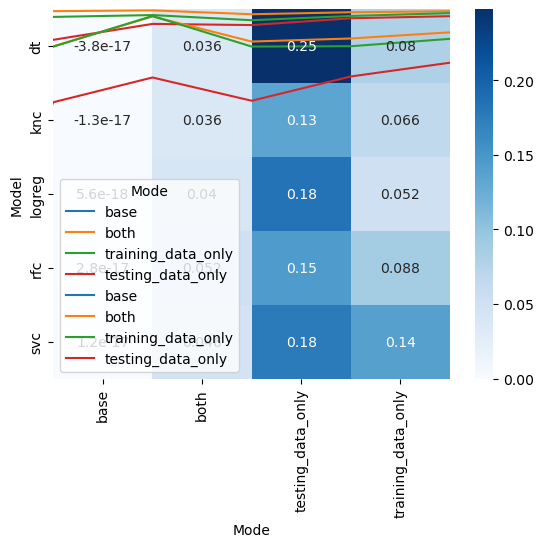

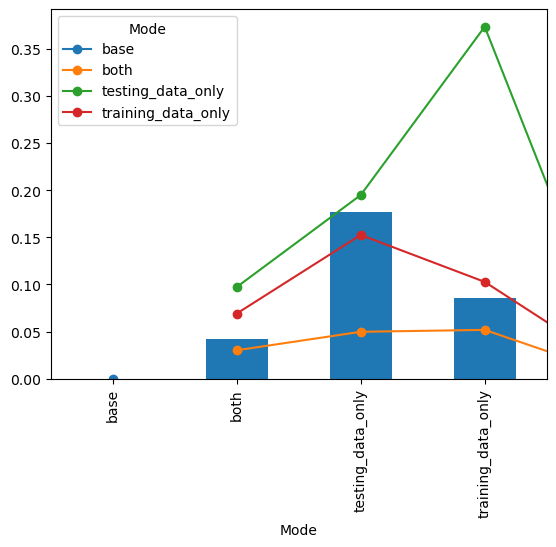

In [ ]:
seaborn.lineplot(data=classification_df, x="Level", y="acc_drop", hue="Mode")
seaborn.lineplot(data=regression_df, x="Level", y="acc_drop", hue="Mode")


pivot = classification_df.groupby(["Model","Mode"])["acc_drop"].mean().unstack()

seaborn.heatmap(pivot, annot=True, cmap="Blues")
classification_df.groupby(["Method","Mode"])["acc_drop"].mean().unstack().plot(marker='o')
classification_df.groupby("Mode")["acc_drop"].mean().plot(kind="bar")